# **Ecole Polytechnique, 2024-2025, APM_3XO62_EP**

### **PROJET 7 : Copules et modélisation de la dépendance entre variable aléatoires**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.random as npr
import scipy.stats as sps

#### **Problématique :**
La question de la dépendance entre des variables aléatoires est centrale dans beaucoup
de phénomènes aléatoires et doit être prise en compte dans la modélisation. Le théorème de Sklar
caractérise la loi d’un vecteur aléatoire comme la donnée des lois marginales et d’une fonction copule
qui décrit la structure de dépendance du vecteur. L’objectif de ce projet est de montrer ce théorème, puis
d’étudier quelques familles de copules qui sont utilisées pour modéliser la dépendance. Une application
au risque de crédit en finance est proposée à la fin du projet.

Pour $d \in \mathbb{N}$, $d \geq 2$, on appelle \emph{copule de dimension $d$} une fonction 
$C : [0, 1]^d \rightarrow [0, 1]$ telle qu’il existe des variables aléatoires $U_1, \ldots, U_d$ 
uniformes sur $[0, 1]$ avec lesquelles
$$
\forall u \in [0,1]^d, \quad C(u_1, \ldots, u_d) = \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d).
$$
Ainsi, une copule est la fonction de répartition d’un vecteur aléatoire dont les marginales suivent 
la loi uniforme sur $[0, 1]$.

### **Premières propriétés, bornes de Fréchet-Hoeffding.**

**T1. Calculons $C(u_1,1,\dots,1)$ et $C(0,u_2,\dots,u_d)$ pour $u_1,\dots,u_d \in [0, 1]$**

On a :
$$
\forall u = (u_1, \ldots, u_d), \quad C(u_1,1, \ldots, 1) = \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq 1) = \mathbb{P}(U_1 \leq u_1)
$$

car $U_1 \sim \mathcal{U}([0,1])$

Donc 
$$
C(u_1, 1, \ldots, 1) = u_1
$$
Et on a : 
$$
C(0, u_2, \ldots, u_d) = \mathbb{P}(U_1 \leq 0, \ldots, U_d \leq u_d) = 0
$$

**Montrer que pour tout $2 \leq d' < d$,**

$$
(u_1, \ldots, u_{d'}) \mapsto C(1, \ldots, 1, u_1, \ldots, u_{d'})
$$

**est une copule de dimension $d'$.**

C est une copule de dimension $d$ donc $\exists U_1, \ldots, U_d$ des variables aléatoires uniformes sur $[0,1]$ t.q.

$$
\forall u \in [0,1]^d, \quad C(u_1, \ldots, u_d) = \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d)
$$

On considère les variables $U_{d-d'+1}, \ldots, U_{d}$ et on les note $U'_1, \ldots, U'_{d'}$

En remarquant que :

$$
\mathbb{P}(U_1 \leq 1, \ldots, U_{d-d'} \leq 1, U'_1 \leq u_1, \ldots, U'_{d'} \leq u_{d'}) =
$$
$$
\mathbb{P}(U'_1 \leq u_1, \ldots, U'_{d'} \leq u_{d'})
$$

car $\forall i \in \{1, \ldots, d-d'\}, \quad \mathbb{P}(U_i \leq 1) = 1$

Alors 
$$
(u_1, \ldots, u_{d'}) \mapsto C(1,\ldots,1,u_1, \ldots, u_{d'})
$$
est une copule de dimension $d'$ vu l'existence de $U'_1, \ldots, U'_{d'}$ uniformes sur $[0,1]$ qui vérifient la définition.

**T2. Calculons $C$ lorsque $U_1, \ldots, U_d$ sont indépendantes et lorsque $U_1 = \cdots = U_d$.**

Si $U_1, \ldots, U_d$ sont indépendants, alors : 
$$
C(u_1, \ldots, u_d) = \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d) = \prod_{i=1}^d u_i
$$

Si $u_1 = \cdots = u_d$ alors

$$
\begin{aligned}
    C(u_1, \ldots, u_d)
    &= \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d) \\
    &= \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d) \\
    &= \mathbb{P}\left(U_i \leq \min_{i \in \{1, \ldots, d\}} u_i\right) \\
    &= \min_{i \in \{1, \ldots, d\}} u_i.
\end{aligned}
$$

**T3. On définit :**
$$\begin{align*}
C^+(u) &= \min_{1 \leq i \leq d} u_i, \\
C^-(u) &= \max\left( \sum_{i=1}^d u_i - (d - 1),\ 0 \right).
\end{align*}$$

**Montrons que :**
$$
\forall u \in [0,1]^d, \quad C^-(u) \leq C(u) \leq C^+(u).
$$

On note : $$ i_0 = \arg\min_i u_i, \quad i \in \{1, \ldots, d\} $$

On a : $$ \left\{ U_1 \leq u_1, \ldots, U_d \leq u_d \right\} \subset \left\{ U_{i_0} \leq u_{i_0} \right\} $$

Donc : 
$$ C(u) \leq C^+(u) $$
Si $d = 2$ :
$$
\begin{align*}
\mathbb{P}(U_1 \leq u_1, U_2 \leq u_2) &= \mathbb{P}(U_1 \leq u_1) + \mathbb{P}(U_2 \leq u_2) - \mathbb{P}(U_1 \leq u_1 \cup U_2 \leq u_2)
\end{align*}
$$

Donc :
$$ C(u) \geq u_1 + u_2 - 1 \quad (\text{car } \mathbb{P}(U_1 \leq u_1 \cup U_2 \leq u_2) \leq 1) $$

Or,
$$ C(u) \geq 0 $$

D'où :
$$ C(u) \geq C^-(u) $$

Soit  $d \geq 2$, on suppose que la propriété est vraie pour $d$ et montrons-la pour $d+1$ :
$$
\begin{align*}
C(u) &= \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d, U_{d+1} \leq u_{d+1}) \\
&= \mathbb{P}(U_1 \leq u_1, \ldots, U_d \leq u_d) + \mathbb{P}(U_{d+1} \leq u_{d+1}) - \mathbb{P}((U_1 \leq u_1, \ldots, U_d \leq u_d)\cup(U_{d+1} \leq u_{d+1}))
\end{align*}
$$
Donc :
$$ C(u) \geq C(u_1, \ldots, u_d,1) + u_{d+1} - 1 $$

Or par H.R. et en utilisant le fait que $C(u_1, \ldots, u_d,1)$ est une copule de dimension d, Alors :
$$ C(u_1, \ldots, u_d,1) \geq \max\left( \sum_{i=1}^{d} u_i - (d-1), 0 \right) $$

$$ \Rightarrow C(u) \geq C^-(u)  $$

**À quelle condition a-t-on $C = C^+$ ?**

En s'inspirant de la question précédente, on conjecture que : $$C = C^+ \Longleftrightarrow U_1 = \cdots = U_d$$
En effet, l'implication inverse est conséquence directe de la question précédente.
Pour l'implication directe :
On suppose que $C = C^+$
Or, si on note : $$ i_0 = \arg\min_i u_i, \quad i \in \{1, \ldots, d\} $$
Alors : on a, d'une part, $$ \left\{ U_1 \leq u_1, \ldots, U_d \leq u_d \right\} \subset \left\{ U_{i_0} \leq u_{i_0} \right\} $$
et d'une autre part :  $C(u) = C^+(u)$
Donc : $$ \left\{ U_1 \leq u_1, \ldots, U_d \leq u_d \right\} = \left\{ U_{i_0} \leq u_{i_0}\right\} $$
D'où, si $u_1 = \cdots = u_d$
Alors : $$ \left\{ U_1 \leq u_1, \ldots, U_d \leq u_1 \right\} = \left\{ U_{i} \leq u_{1}\right\} \quad i \in \{1, \ldots, d\} $$ 
Donc $$ \left\{ U_{j} \leq u_1\right\} = \left\{ U_{i} \leq u_{1}\right\}$$
Par suite, $$ U_{j} = U_{i} $$
Finalement : $$ C = C^+ \Longleftrightarrow U_1 = \cdots = U_d $$

**T4. Vérifions que, pour d=2 :**
 $(U_1,U_2)$ a pour copule $C^+ \Longleftrightarrow \mathbb{P}(U_1 = 1 - U_2 ) = 1 $.

**Montrons l'implication directe :**
Soit $n \in \mathbb{N^*}$,

On a :  
$$
\left\{0 < 1 - (U_1 + U_2)\right\}  \subset  \bigcup_{n \in \mathbb{N^*}} \left\{ U_1 < 1/n, U_2 < 1-1/n \right\}
$$

Or  
$$
\mathbb{P}(\left\{ U_1 < 1/n, U_2 < 1-1/n \right\}) 
= C^+(1/n,1-1/n)
=0
$$

Donc  
$$
\mathbb{P}(\left\{0 < 1 - (U_1 + U_2)\right\}) \leq 0
$$

D'où :
$$
\mathbb{P}(\left\{0 < 1 - (U_1 + U_2)\right\}) = 0
$$

Et on a :
$$  
\left\{0 < (U_1 + U_2) - 1\right\}  \subset  \bigcup_{n \in \mathbb{N^*}} \left\{ U_1 > 1/n, U_2 > 1-1/n \right\}
$$

Or
$$
\mathbb{P}(\left\{ U_1 > 1/n, U_2 > 1-1/n \right\}) = \mathbb{P}(U_1 > 1/n) + \mathbb{P}(U_2 > 1 - 1/n) - \mathbb{P}(\left\{U_1 > 1/n\right\} \cup \left\{U_2 > 1 - 1/n\right\})
$$

D'où :
$$
\mathbb{P}(\left\{ U_1 > 1/n, U_2 > 1-1/n \right\}) = 0
$$

Finalement :
$$
\mathbb{P}(\left\{0 < (U_1 + U_2) - 1\right\}) = 0
$$

Et on peut conclure que $$ \mathbb{P}(U_1 = 1 - U_2) = 1 $$

**Déduisons que pour $3 \leq d$, $C^+$ n'est pas une copule.**

Soit $3 \leq d$,
$$
$$
On peut remarquer que si $C^+$ était une copule, alors si on remplace k éléments par 1, on obtient une copule de dimension d-k pour k entre 0 et d, et dont la copule coincide avec $C^+$.
Ainsi, en ne laissant respectivement que $(U_1,U_2)$ puis $(U_1,U_3)$ et enfin $(U_2,U_3)$,
On obtient :
$$ 
\mathbb{P}(U_1 = 1 - U_2) = 
\mathbb{P}(U_1 = 1 - U_3) = 
\mathbb{P}(U_3 = 1 - U_2) = 1
$$

Donc :
$$
U_1 = 1 - U_1 (p.s)
$$
Absurde, d'où le résultat désiré.

**T5. Montrons que C est continue.**

C étant la fonction de répartition du vecteur $(U_1,\dots,U_d)$ dont les composantes suivent tous la loi uniforme sur $[0,1]$, alors elle ne donne de masse à aucun point, donc elle est bien continue.

**T6. Soient $V_1,\dots, V_d$ des variables aléatoires uniformes sur $[0, 1]$ de copule $C^′$ et $B$ une variable
aléatoire de $Bernoulli$ de paramètre $p$ indépendante de $U$ et $V$ . Montrons que $BU + (1 − B)V$ est un
vecteur aléatoire dont les marginales suivent la loi uniforme sur $[0, 1]$ de copule $pC + (1 − p)C^′$.**

Par la formule de probabilité totale et en utilisant le fait que $B$,$U$ et $V$ sont indépendants, on a pour $0\leq x \leq 1$ :
$$
\mathbb{P}(BU_i+(1-B)V_i \leq x)=p*\mathbb{P}(U_i \leq x) + (1-p)*\mathbb{P}(V_i \leq x) = x
$$
Et on a, encore une fois en utilisant les mêmes arguments :
$$
\mathbb{P}(BU_1+(1-B)V_1 \leq x_1, \dots, BU_d+(1-B)V_d \leq x_d) = pC(x) + (1 − p)C^′(x)
$$
Finalement, $BU + (1 − B)V$ est un vecteur aléatoire dont les marginales suivent la loi uniforme sur $[0, 1]$ de copule :$$pC + (1 − p)C^′$$

**Déduisons que l'ensemble des copules est convexe.**

Ceci est une conclusion directe de la question précédente.
$$
$$
En effet, si on se donne deux copules $C$ et $C^′$ et $p \in [0,1]$,
$$
$$
Alors, en considérant une variable aléatoir $B$ de $Bernoulli$ de paramètre $p$ indépendante de $U$ et $V$, la question précédente nous dit que : $BU + (1 − B)V$ est un vecteur aléatoire dont les marginales suivent la loi uniforme sur $[0, 1]$ de copule $pC + (1 − p)C^′$
$$
$$
Donc, $pC + (1 − p)C^′$ est une copule aussi, ce qui assure la convexité de l'ensemble de ces derniers.

### **Le théorème de Sklar**

**On considère d variables aléatoires réelles $X_1,\dots, X_d$. Pour $i \in {1, . . . , d}$, on note $F_i(x) = \mathbb{P}(X_i \leq x)$ la fonction de répartition de $X_i$, que l’on suppose continue.**
$$
$$
**L'objectif de cette partie est de montrer qu'il existe une unique copule $C_X : [0, 1]^d \rightarrow [0, 1]$ telle que** 
$$
\forall x \in \mathbb{R}^d, \quad P(X_1 \leq x_1, \ldots, X_d \leq x_d) = C_X(F_1(x_1), \ldots, F_d(x_d)). \quad (7.1)
$$  

**La fonction $C_X$ est appelée la copule du vecteur $X = (X_1, \ldots, X_d)$.**

**T7. On commence par supposer les fonctions $F_i$ strictement croissantes, et on pose $U_i = F_i(X_i)$.**
**Montrons que $U_1,\dots, U_d$ suivent la loi uniforme sur $[0, 1]$.**

Les $F_i$ étant continues et strictement monotones, alors elles sont bijectives.
$$
$$
Ainsi, pour $x_i \in [0,1]$ :
$$
\mathbb{P}(U_i \leq x_i)=
\mathbb{P}(F_i(X_i) \leq x_i)=
\mathbb{P}(X_i \leq F_i^{-1}(x_i))=
F_i(F_i^{-1}(x_i))=
x_i
$$
Donc, $U_1,\dots, U_d$ suivent la loi uniforme sur $[0, 1]$

**Montrer que la copule associée à $U_1,\dots, U_d$ est l’unique fonction continue $C_X : [0, 1]^d \rightarrow [0, 1]$ satisfaisant $(7.1)$.**

En utilisant l'équivalence suivante ( due à la stricte croissance des $F_i$ ) : $X_i \leq x_i \Longleftrightarrow F_i(X_i) \leq F_i(x_i)$
$$
$$
Alors, on a directement : 
$$
\forall x \in \mathbb{R}^d, \quad P(X_1 \leq x_1, \ldots, X_d \leq x_d) = C_X(F_1(x_1), \ldots, F_d(x_d))
$$
Donc la copule associée à $U_1,\dots,U_d$ est bien une fonction qui vérifie $(7.1)$.
$$
$$
L'unicité est directe, elle découle directement de la définition et du fait que les $F_i$ décrivent l'intervalle $[0,1]$.

**T8. On ne suppose plus les fonctions de répartitions strictement croissantes et on pose pour $u \in ]0,1[$,**

$$
F_i^{-1}(u) = \inf\{x \in \mathbb{R}, F_i(x) > u\}.
$$

**Montrons que $F_i(F_i^{-1}(u)) = u$.**

Les $F_i$ étant continues et la borne $inf$ étant une limite, on a : $u \leq F_i(F_i^{-1}(u))$
$$
$$
Or : pour $x \leq F_i^{-1}(u)$, on a $F_i(x) \leq u$
$$
$$
Donc, par continuité de $F_i$, on obtient : $F_i(F_i^{-1}(u)) \leq u$
$$
$$
D'où : $F_i(F_i^{-1}(u)) = u$

**Montrons que $F_i(x) \leq u \iff x \leq F_i^{-1}(u)$**

Si : $F_i(x) \leq u $, alors : $F_i(x) \leq F_i(F_i^{-1}(u))$ car $F_i(F_i^{-1}(u)) = u$
$$
$$
Donc, étant donnée la croissance de $F_i$, alors : $x \leq F_i^{-1}(u)$
$$
$$
Si : $x \leq F_i^{-1}(u)$, alors la croissance de $F_i$ donne : 
$$
$$
$F_i(x) \leq F_i(F_i^{-1}(u))$, d'où $F_i(x) \leq u$
$$
$$
Finalement : $F_i(x) \leq u \iff x \leq F_i^{-1}(u)$

**Déduisons que $U_i = F_i(X_i)$ suit la loi uniforme sur $[0,1]$, que $X_i = F_i^{-1}(U_i)$ p.s., puis que la copule associée à $U_1, \ldots, U_d$ est l'unique fonction continue $C_X : [0,1]^d \to [0,1]$ satisfaisant $(7.1)$.**

L'équivalence qu'on vient de montrer nous permet de dire que, pour $x_i \in [0,1]$ :
$$
\mathbb{P}(U_i \leq x_i)=
\mathbb{P}(F_i(X_i) \leq x_i)=
\mathbb{P}(X_i \leq F_i^{-1}(x_i))=
F_i(F_i^{-1}(x_i))=
x_i
$$
Donc $U_i = F_i(X_i)$ suit la loi uniforme sur $[0,1]$


Et on a : $F_i(X_i) \leq u \iff X_i \leq F_i^{-1}(u) \iff F_i^{-1}(F_i(X_i)) \leq F_i^{-1}(u)$
$$
$$
Donc : $X_i \leq F_i^{-1}(u) \iff F_i^{-1}(U_i) \leq F_i^{-1}(u)$
$$
$$
Et, comme $F_i^{-1}$ parcours $\mathbb{R}$, alors $X_i = F_i^{-1}(U_i)$ p.s.

En utilisant le fait que $X_i = F_i^{-1}(U_i)$ p.s. et que $F_i(F_i^{-1}(u)) = u$ :
$$
\forall x \in \mathbb{R}^d, \mathbb{P}(X_1 \leq x_1, \ldots, X_d \leq x_d) = C_X(F_1(x_1), \ldots, F_d(x_d))
$$
Donc la copule associée à $U_1,\dots,U_d$ est bien une fonction qui vérifie $(7.1)$.
$$
$$
L'unicité est directe, elle découle directement de la définition et du fait que les $F_i$ décrivent l'intervalle $[0,1]$ étant donné leur continuité et limites aux bornes.

**T9. En déduire que si $Y = (Y_1, \ldots, Y_d)$ est un vecteur aléatoire, $Y$ a même loi que $X$ si, et seulement si**  
$$
\forall u \in [0, 1]^d, \quad C_Y(u) = C_X(u) \quad \text{et} \quad \forall i \in \{1, \ldots, d\}, \quad Y_i \text{ a même loi que } X_i.
$$

Pour l'implication directe, $Y_i$ a même loi que $X_i$ est directe, donc ils ont même fonction de répartition, d'où $C_X = C_Y$ étant donnée leur unicité.

Pour l'implication réciproque, l'égalité entre $C_X$ et $C_Y$ et le fait que les fonctions de répartition sont similaires par la condition restante permet de remonter aux expressions de $\mathbb{P}(X_1 \leq x_1, \ldots, X_d \leq x_d)$ et $\mathbb{P}(Y_1 \leq x_1, \ldots, Y_d \leq x_d)$ qui seront égales, chose qui assurent l'égalité en loi de $X$ et $Y$.

**T10. On considère $f_1, \ldots, f_d$ fonctions réelles continues strictement croissantes. Montrer que les vecteurs $(f_1(X_1), \ldots, f_d(X_d))$ et $(X_1, \ldots, X_d)$ ont la même copule.**

La première conlusion à laquelle on peut arriver est que les $f_i$ sont toutes bijectives.
$$
$$
Ceci nous permet de dire que la fonction de répartition de $f_i(X_i)$ n'est rien d'autre que $F_i\circ f_i^{-1}$
$$
$$
Ainsi :
$$
\mathbb{P}(X_1 \leq x_1, \ldots, X_d \leq x_d) = C_X(F_1(x_1), \ldots, F_d(x_d))
$$ 
et
$$
\mathbb{P}(f_1(X_1) \leq f_1(x_1), \ldots, f_d(X_d) \leq f_d(x_d)) = C_{f(X)}(F_1(x_1), \ldots, F_d(x_d))
$$
Et comme : $\mathbb{P}(X_1 \leq x_1, \ldots, X_d \leq x_d) = \mathbb{P}(f_1(X_1) \leq f_1(x_1), \ldots, f_d(X_d))$ car les $f_i$ sont bijectives, 
$$
$$
Alors : $C_X(F_1(x_1), \ldots, F_d(x_d)) = C_{f(X)}(F_1(x_1), \ldots, F_d(x_d))$
$$
$$
Or, les $F_i$ parcourent $[0,1]$ en entier, donc $C_X = C_{f(X)}$, et on obtient le résultat désiré.

### **Quelques familles de copules**

**T11. Montrons que pour toute copule Gaussienne, il existe un vecteur gaussien $X$ de dimension $d$, centré et de matrice de covariance $\Sigma$ telle que**
$$
\Sigma_{ii} = 1 \quad \text{pour } 1 \le i \le d
$$
**qui a cette copule.**

En utilisant la question précédente, on prend :
$$
\forall i \in \left\{1, \dots, d\right\} \space \space f_{i}(x)=\frac{x - \mu_i}{\sigma_i}
$$
Les $f_i$ étant strictement croissantes et continues, alors on a : $(f_1(X_1), \ldots, f_d(X_d))$ et $(X_1, \ldots, X_d)$ ont la même copule.
$$
$$
Et comme $f_i(X_i) \sim \mathcal{N}(0,1) \space \space  \forall i \in \left\{1, \dots, d\right\}$
$$
$$
Alors, on obtient le résultat désiré.

**S1. Pour simuler la loi gaussienne centrée réduite $\mathcal{N}(0,1)$ on utilise la méthode de Box-Muller :**

On commence par construire deux variables aléatoires indépendantes de loi uniformes : 
$$
U_1 \sim \mathcal{U}([0,1]) ~~~ et ~~~U_2 \sim \mathcal{U}([0,1])
$$
Puis on pose : 
$$
Y = \sqrt{-2\log(U_1)} \cdot \cos(2 \pi U_2)
$$
Alors,
$$
Y \sim \mathcal{N}(0,1)
$$
**Pour constriure  $X\sim \mathcal{N}_d(0, \Sigma)$ à partir de d variables aléatoires gaussiennes centrées réduites indépendantes :**
$$
$$
On peut commencer par rassembler ces variables $Y_1$,...,$Y_d$ sous la forme d'un vecteur aléatoire : 
$$
Y = \begin{pmatrix}
Y_1 \\
... \\
Y_d
\end{pmatrix}
$$
Par définition, $\Sigma$ est une matrice symétrique définie positive donc il existe une matrice L telle que :
$$
\Sigma = LL^{\top}
$$
On peut alors définir X tel que :
$$
X = LY
$$
On vérifie que 
$$
E[X]= L E[Y] = 0
$$
$$
\mathrm{Cov}(X)=L \, \mathrm{Cov}(Y) \, L^{\top}=L I_d L^{\top}=L L^{\top}=\Sigma
$$
X est donc le vecteur recherché.
$$
$$
**On conclu grâce au théorème de Sklar, démontré précédemment, qui nous permet de montrer que $(\Phi(X_1), \ldots, \Phi(X_d))$ est un vecteur dont la fonction de répartition est la copule gaussienne de matrice de covariance $\Sigma$.**

**S2.**

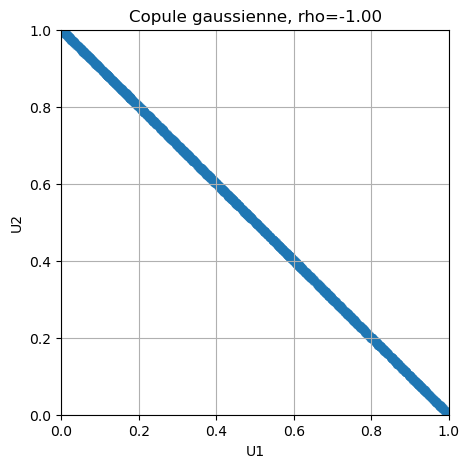

rho = -1.00
Corr(U1,U2) estimée = -1.0000, IC95% = [-1.0572, -0.9428]



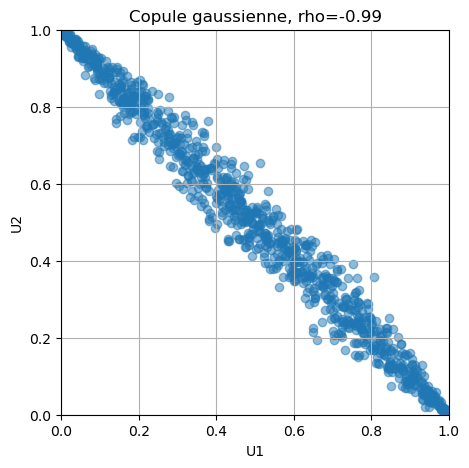

rho = -0.99
Corr(U1,U2) estimée = -0.9888, IC95% = [-1.0463, -0.9312]



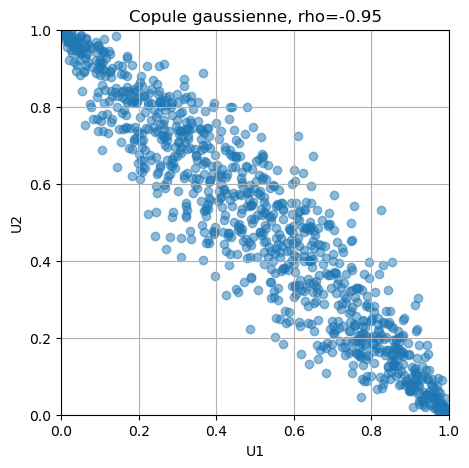

rho = -0.95
Corr(U1,U2) estimée = -0.9423, IC95% = [-0.9999, -0.8848]



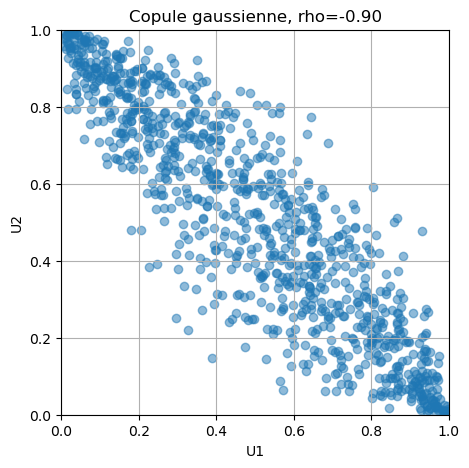

rho = -0.90
Corr(U1,U2) estimée = -0.8992, IC95% = [-0.9540, -0.8445]



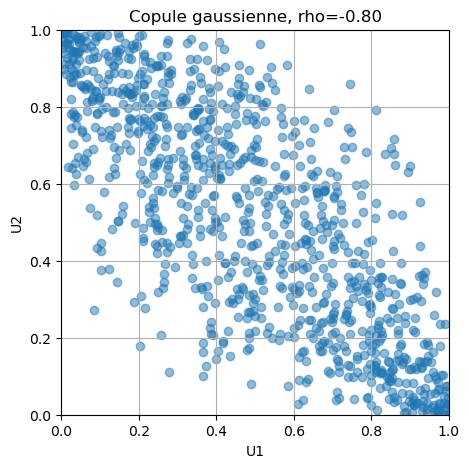

rho = -0.80
Corr(U1,U2) estimée = -0.7665, IC95% = [-0.8234, -0.7096]



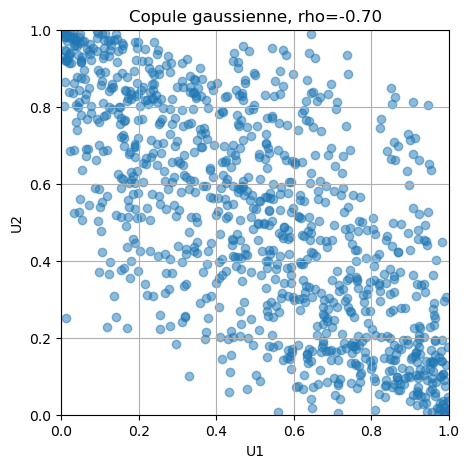

rho = -0.70
Corr(U1,U2) estimée = -0.6859, IC95% = [-0.7443, -0.6275]



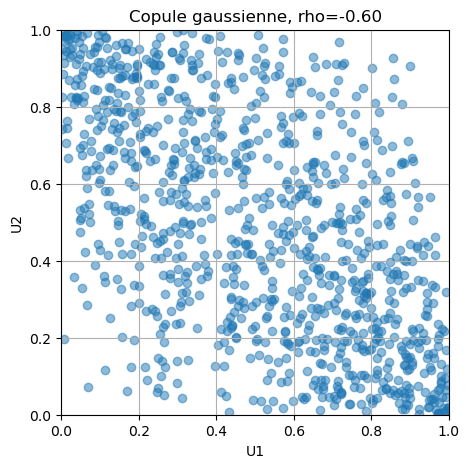

rho = -0.60
Corr(U1,U2) estimée = -0.5679, IC95% = [-0.6264, -0.5095]



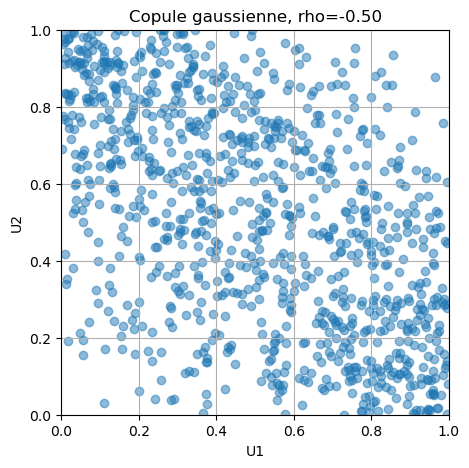

rho = -0.50
Corr(U1,U2) estimée = -0.5198, IC95% = [-0.5776, -0.4621]



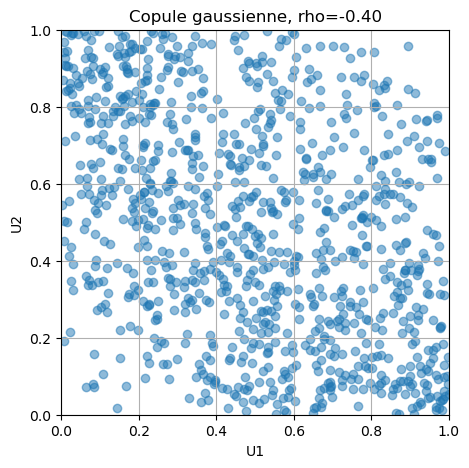

rho = -0.40
Corr(U1,U2) estimée = -0.3887, IC95% = [-0.4489, -0.3285]



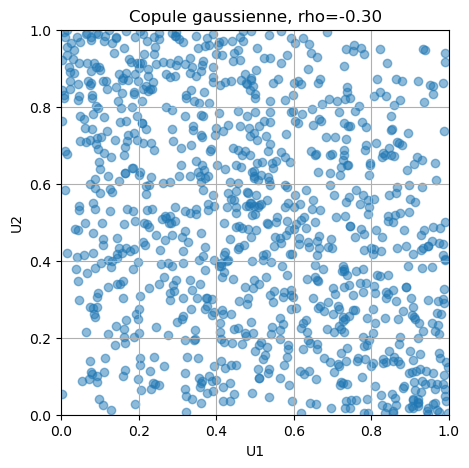

rho = -0.30
Corr(U1,U2) estimée = -0.3051, IC95% = [-0.3679, -0.2424]



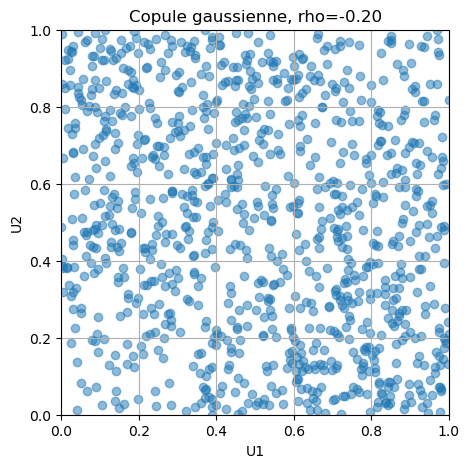

rho = -0.20
Corr(U1,U2) estimée = -0.1961, IC95% = [-0.2561, -0.1360]



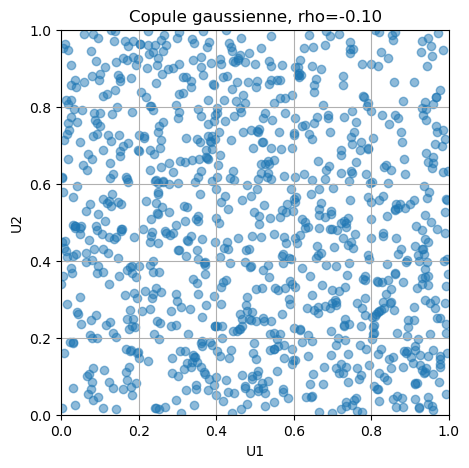

rho = -0.10
Corr(U1,U2) estimée = -0.1258, IC95% = [-0.1865, -0.0651]



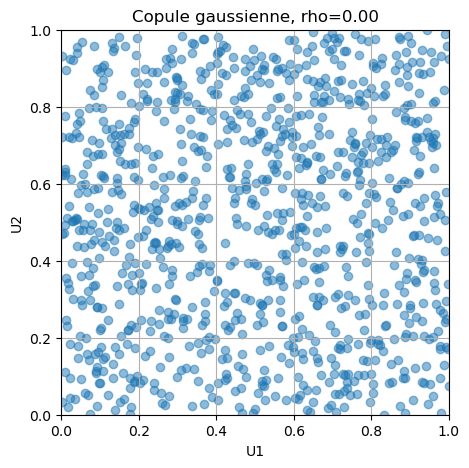

rho = 0.00
Corr(U1,U2) estimée = 0.0301, IC95% = [-0.0312, 0.0913]



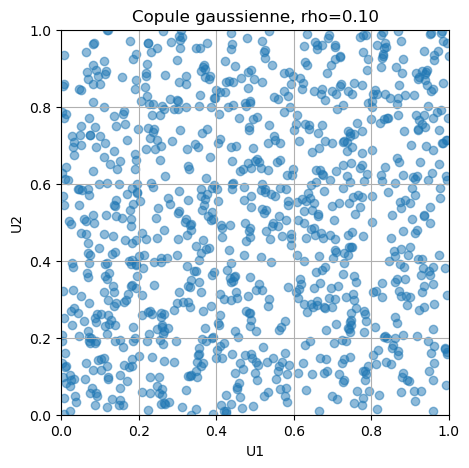

rho = 0.10
Corr(U1,U2) estimée = 0.1171, IC95% = [0.0546, 0.1796]



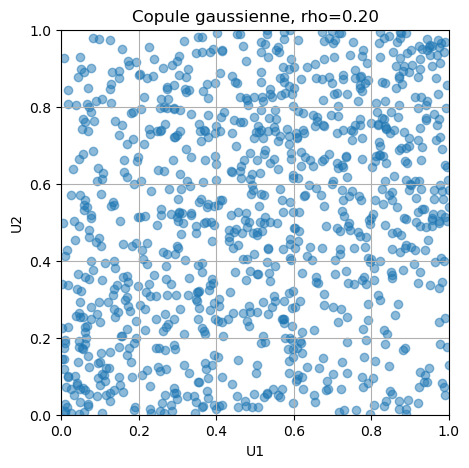

rho = 0.20
Corr(U1,U2) estimée = 0.2244, IC95% = [0.1624, 0.2863]



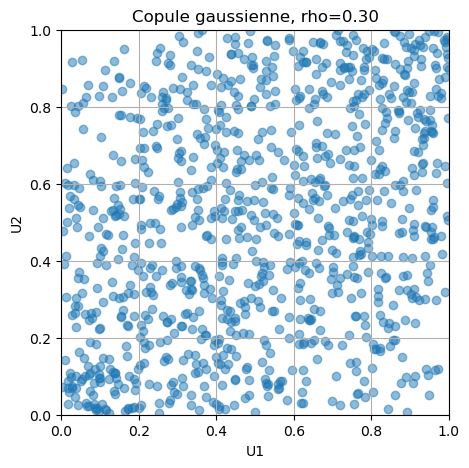

rho = 0.30
Corr(U1,U2) estimée = 0.2959, IC95% = [0.2346, 0.3571]



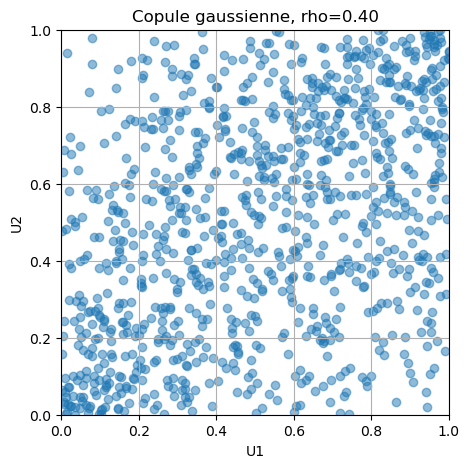

rho = 0.40
Corr(U1,U2) estimée = 0.4036, IC95% = [0.3424, 0.4648]



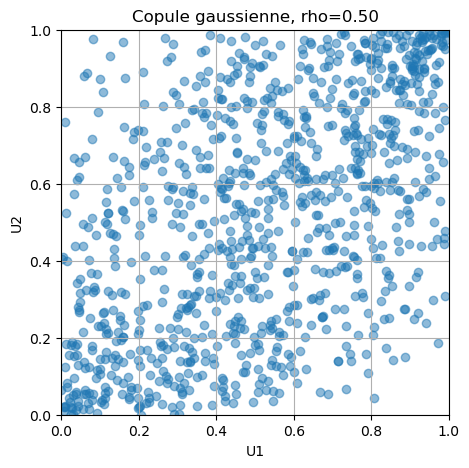

rho = 0.50
Corr(U1,U2) estimée = 0.5172, IC95% = [0.4572, 0.5772]



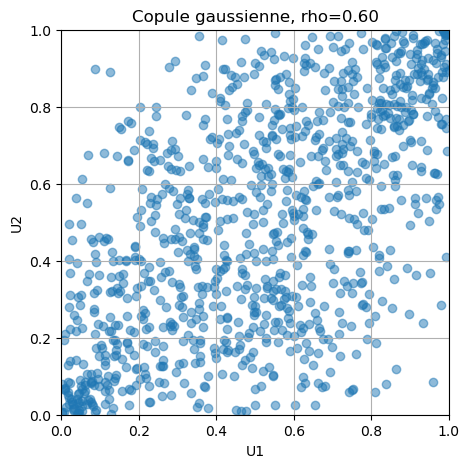

rho = 0.60
Corr(U1,U2) estimée = 0.5900, IC95% = [0.5300, 0.6501]



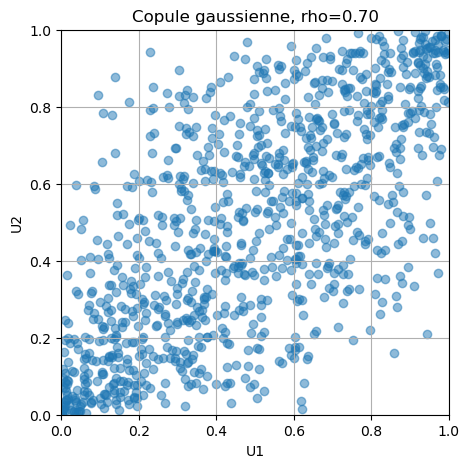

rho = 0.70
Corr(U1,U2) estimée = 0.6782, IC95% = [0.6195, 0.7369]



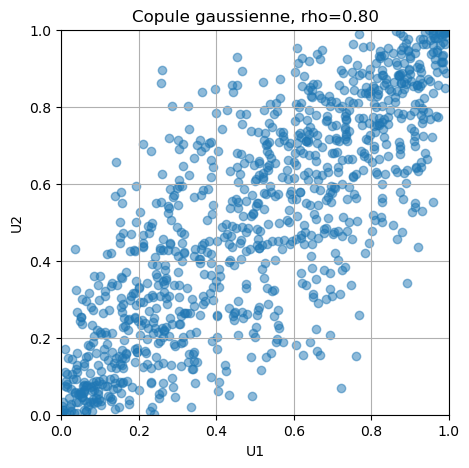

rho = 0.80
Corr(U1,U2) estimée = 0.8036, IC95% = [0.7479, 0.8592]



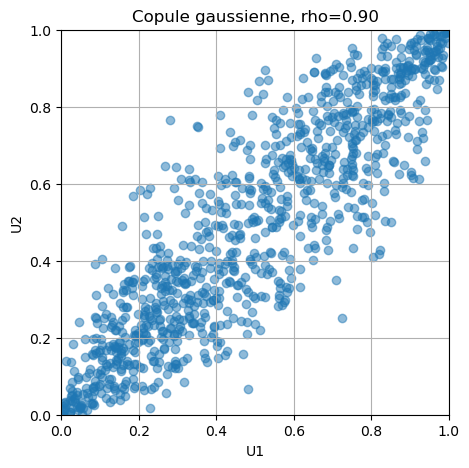

rho = 0.90
Corr(U1,U2) estimée = 0.8886, IC95% = [0.8335, 0.9436]



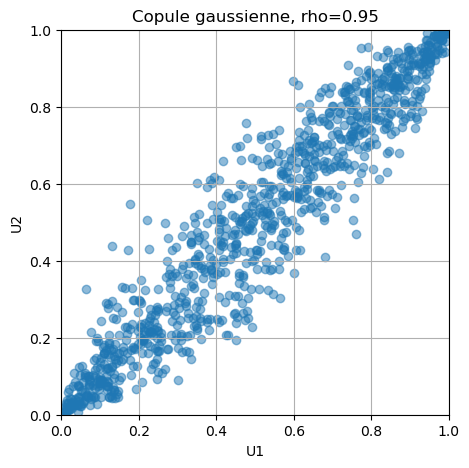

rho = 0.95
Corr(U1,U2) estimée = 0.9531, IC95% = [0.8993, 1.0069]



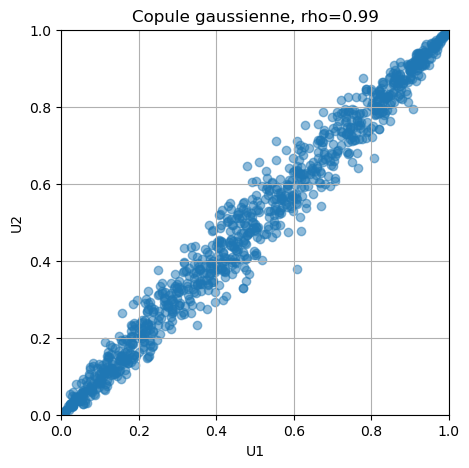

rho = 0.99
Corr(U1,U2) estimée = 0.9888, IC95% = [0.9337, 1.0440]



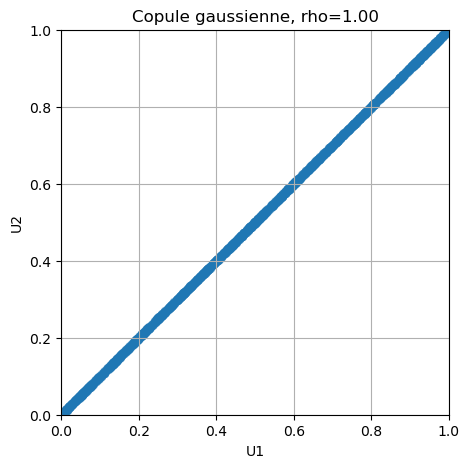

rho = 1.00
Corr(U1,U2) estimée = 1.0000, IC95% = [0.9439, 1.0561]



In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sps

p = [-1, -0.99, -0.95, -0.9, -0.8, -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0,
     0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1]

n = 1000

def simGauss(rho, n):
    # Box-Muller : génère deux normales standard indépendantes
    u1 = np.random.rand(n)
    u2 = np.random.rand(n)
    Y1 = np.sqrt(-2*np.log(u1))*np.cos(2*np.pi*u2)
    Y2 = np.sqrt(-2*np.log(u1))*np.sin(2*np.pi*u2)
    
    # combinaison linéaire selon la corrélation
    X1 = Y1
    X2 = rho * Y1 + np.sqrt(1 - rho**2) * Y2
    
    return (X1, X2)

for rho in p:
    X1, X2 = simGauss(rho, n)
    
    # transformation en uniforms via la cdf normale
    U1 = sps.norm.cdf(X1)
    U2 = sps.norm.cdf(X2)
    
    # corrélation empirique sur uniforms
    corr_emp = np.corrcoef(U1, U2)[0,1]
    
    # IC95% Monte-Carlo
    products = (U1 - np.mean(U1)) * (U2 - np.mean(U2))
    std_err = np.std(products) / np.sqrt(n) / (np.std(U1)*np.std(U2))
    IC = (corr_emp - 1.96*std_err, corr_emp + 1.96*std_err)
    
    # affichage du nuage de points
    plt.figure(figsize=(5,5))
    plt.scatter(U1, U2, alpha=0.5)
    plt.title(f"Copule gaussienne, rho={rho:.2f}")
    plt.xlabel("U1")
    plt.ylabel("U2")
    plt.xlim(0,1)
    plt.ylim(0,1)
    plt.grid(True)
    plt.show()
    
    # résultats numériques
    print(f"rho = {rho:.2f}")
    print(f"Corr(U1,U2) estimée = {corr_emp:.4f}, IC95% = [{IC[0]:.4f}, {IC[1]:.4f}]")
    print()

### **Copules Archimédiennes**

**T12. Montrons que $\psi$ est strictement décroissante, continue telle que $\psi(0) = 1$ et** 
$
\lim_{t \to +\infty} \psi(t) = 0.
$

On a : $\mathbb{P}(\xi > 0) = 1$ et l'espérance est croissante
$$
$$
Donc : $\psi$ en tant que l'espérance d'une fonction strictement décroissante l'est aussi.
$$
$$
En outre, $t \to \exp(-t\xi)$ étant inférieur à $1$ qui est intégrable et continue pour la variable $t$ sur $\mathbb{R}_+$, alors par le théorème de convergence dominée, $\psi$ est continue sur $\mathbb{R}_+$.
$$
$$
D'où, d'une part : $\psi(0) = \mathbb{E}(1) = 1$
$$
$$
Et, d'autre part, par le théorème de convergence dominée, on a :  $\lim_{t \to +\infty} \psi(t) = \mathbb{E}(0) = 0$

**T13. On considère $d$ variables aléatoires $V_1, \dots, V_d$ indépendantes de loi uniforme sur $[0,1]$, également indépendantes de $\xi$.** 

**On pose** 
$$
U_i = \psi\left( \frac{-\log(V_i)}{\xi} \right).
$$
**Montrons que $U_i$ suit la loi uniforme sur $[0,1]$.**

Conditionnons par $\xi = x$. On sait que $V_i \sim \mathcal{U}[0,1]$ et 
$$
-\log(V_i) \sim \text{Exp}(1).
$$
Alors, conditionnellement à $\xi = x$ :
$$
\frac{-\log(V_i)}{x} \sim \text{Exp}(1/x).
$$

On a
$$
U_i = \psi\left( \frac{-\log(V_i)}{x} \right).
$$
$$
\psi\left( \frac{-\log(V_i)}{x} \right) \le u 
\iff \frac{-\log(V_i)}{x} \ge \psi^{-1}(u).
$$
Cela revient à
$$
V_i \le e^{-x \, \psi^{-1}(u)}.
$$

Ainsi :
$$
\mathbb{P}(U_i \le u \mid \xi = x) = \mathbb{P}(V_i \le e^{-x \, \psi^{-1}(u)}) = e^{-x \, \psi^{-1}(u)}.
$$
En enlevant la condition sur $\xi$ :
$$
\mathbb{P}(U_i \le u) = \mathbb{E}\bigl[e^{- \xi \, \psi^{-1}(u)}\bigr] = \psi\bigl(\psi^{-1}(u)\bigr) = u.
$$

Donc :
$$
\boxed{U_i \sim \mathcal{U}[0,1]}
$$

**Montrons que, pour tout $u \in [0,1]^d$, on a :**
  $$
  \mathbb{P}(U_1 \le u_1, \dots, U_d \le u_d) = \psi\left( \psi^{-1}(u_1) + \cdots + \psi^{-1}(u_d) \right).
  $$

Pour tout $u \in [0,1]^d$, considérons :
$$
\mathbb{P}(U_1 \le u_1, \ldots, U_d \le u_d).
$$

Conditionnons par $\xi = x$. Les $U_i$ sont indépendants conditionnellement à $\xi$ :
$$
\mathbb{P}(U_i \le u_i \mid \xi = x) = e^{-x \, \psi^{-1}(u_i)}.
$$
Donc :
$$
\mathbb{P}(U_1 \le u_1, \ldots, U_d \le u_d \mid \xi = x) 
= \prod_{i=1}^d e^{-x \, \psi^{-1}(u_i)} 
= e^{-x \sum_{i=1}^d \psi^{-1}(u_i)}.
$$

En prenant l'espérance sur $\xi$ :
$$
\mathbb{P}(U_1 \le u_1, \ldots, U_d \le u_d) 
= \mathbb{E}\left[ e^{- \xi \sum_{i=1}^d \psi^{-1}(u_i)} \right] 
= \psi\left( \sum_{i=1}^d \psi^{-1}(u_i) \right).
$$

Ainsi :
$$
\boxed{
\forall u \in [0,1]^d,\ 
\mathbb{P}(U_1 \le u_1, \ldots, U_d \le u_d) 
= \psi\left( \psi^{-1}(u_1) + \cdots + \psi^{-1}(u_d) \right).
}
$$

**S3.**
$$
$$


**Calcul de $\psi$ pour $\xi \sim \Gamma(1/\theta, 1)$**

La densité de la loi Gamma $\Gamma(1/\theta, 1)$ est donnée par :
$$
f_\xi(x) = \frac{1}{\Gamma(1/\theta)} x^{1/\theta - 1} e^{-x}, \quad x > 0.
$$

La transformée de Laplace est définie par :
$$
\psi(t) = \mathbb{E}[e^{-t\xi}] = \int_0^{+\infty} e^{-tx} f_\xi(x)  dx.
$$

En substituant la densité :
$$
\psi(t) = \int_0^{+\infty} e^{-tx} \frac{1}{\Gamma(1/\theta)} x^{1/\theta - 1} e^{-x}  dx = \frac{1}{\Gamma(1/\theta)} \int_0^{+\infty} x^{1/\theta - 1} e^{-(t+1)x}  dx.
$$

On reconnaît la forme de la fonction Gamma :
$$
\int_0^{+\infty} x^{a-1} e^{-b x}  dx = \frac{\Gamma(a)}{b^a} \quad \text{pour} \quad a > 0,  b > 0.
$$

Avec $a = 1/\theta$ et $b = t+1$ :
$$
\int_0^{+\infty} x^{1/\theta - 1} e^{-(t+1)x}  dx = \frac{\Gamma(1/\theta)}{(t+1)^{1/\theta}}.
$$

Ainsi :
$$
\psi(t) = \frac{1}{\Gamma(1/\theta)} \cdot \frac{\Gamma(1/\theta)}{(t+1)^{1/\theta}} = (t+1)^{-1/\theta}.
$$

On obtient finalement :
$$
\boxed{\psi(t) = (1 + t)^{-1/\theta}}
$$

**Simulation de la copule archimédienne**
$$
$$

Pour simuler la copule en dimension $d=2$ pour $\theta \in \{10^{-2}, 10^{-1}, 1, 10, 100\}$ :
$$
$$
Générer $\xi \sim \Gamma(1/\theta, 1)$
$$
$$
Générer $V_1, V_2 \sim \mathcal{U}([0,1])$ indépendantes
$$
$$
Calculer :
$$
$$
$$
U_1 = \left( \frac{\xi}{\xi - \ln V_1} \right)^{1/\theta}, \quad U_2 = \left( \frac{\xi}{\xi - \ln V_2} \right)^{1/\theta}
$$

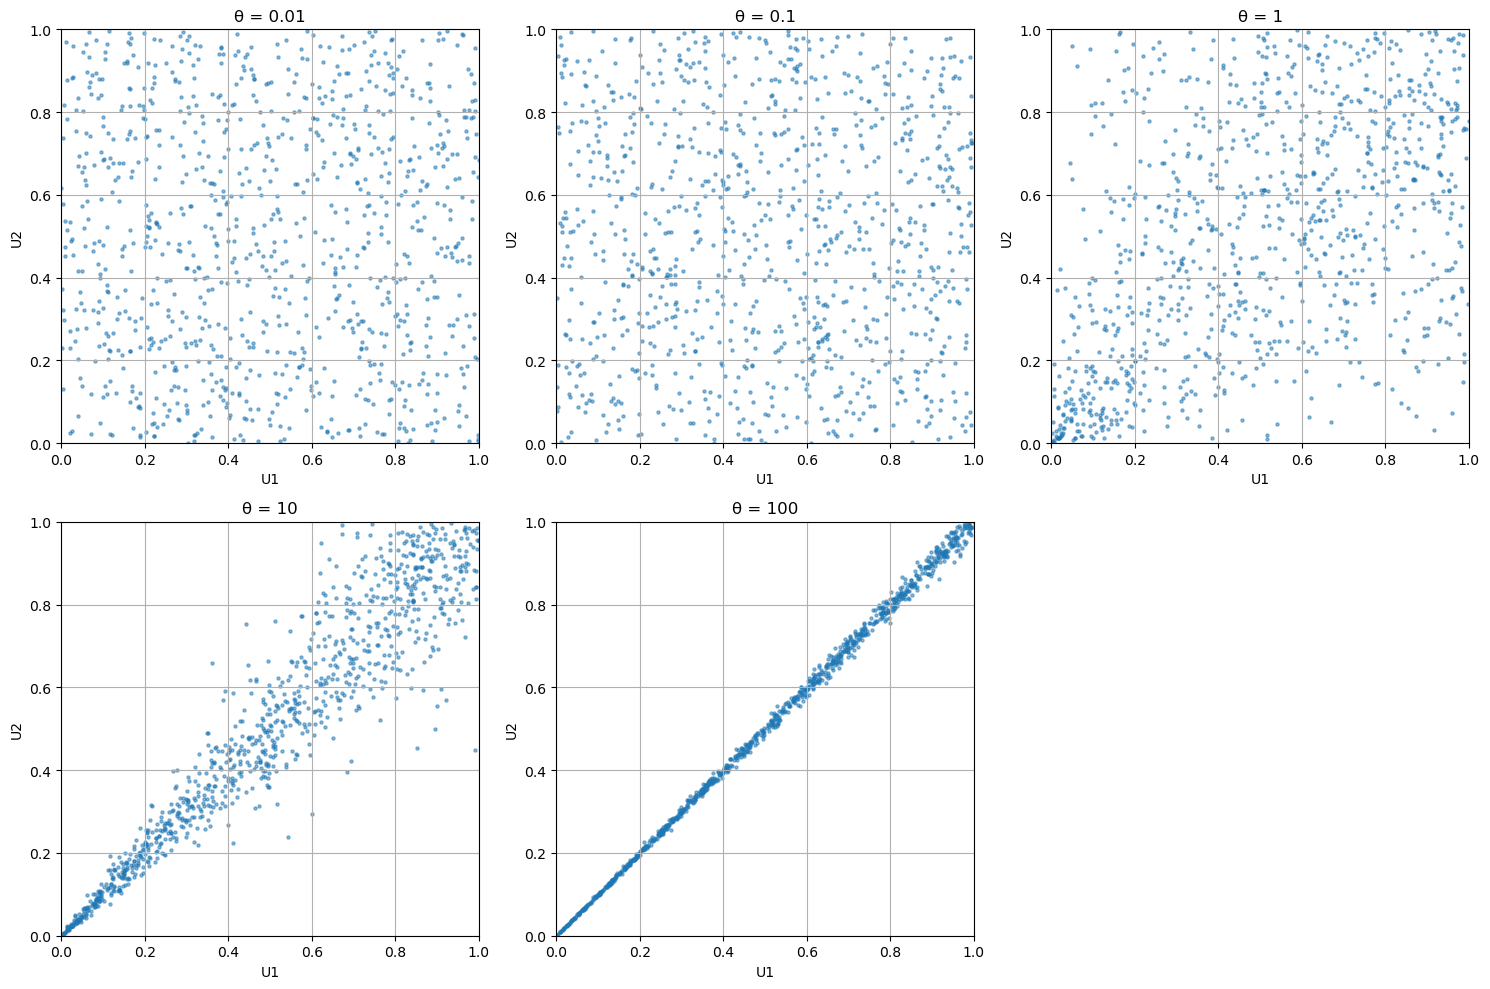

In [4]:
import numpy as np
import matplotlib.pyplot as plt

n = 1000  # nombre de points
theta_list = [0.01, 0.1, 1, 10, 100]

plt.figure(figsize=(15, 10))
for i, theta in enumerate(theta_list):
    shape = 1.0 / theta
    xi = np.random.gamma(shape=shape, scale=1.0, size=n)
    v1 = np.random.uniform(size=n)
    v2 = np.random.uniform(size=n)
    u1 = (xi / (xi - np.log(v1))) ** (1 / theta)
    u2 = (xi / (xi - np.log(v2))) ** (1 / theta)
    
    plt.subplot(2, 3, i+1)
    plt.scatter(u1, u2, s=5, alpha=0.5)
    plt.title(f'θ = {theta}')
    plt.xlabel('U1')
    plt.ylabel('U2')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)

plt.tight_layout()
plt.show()

**Commentaires sur les résultats simulés**

$\theta = 0.01$ : Dispersion uniforme, dépendance très faible (proche de l'indépendance)
$\theta = 0.1$ : Légère concentration le long de la diagonale, dépendance faible
$\theta = 1$ : Dépendance modérée, queue inférieure visible
$\theta = 10$ : Forte concentration diagonale, queue inférieure marquée
$\theta = 100$ : Dépendance quasi-comonotone, accumulation forte en (0,0)

### **Une application au risque de crédit**

**S4. a)**
$$
$$
On considère $ d = 100 $ entreprises avec des temps de défaut $ T_i = -\frac{1}{\lambda} \log(U_i) $ où $ \lambda = 0.02 $. Le nombre de défauts avant $ T = 5 $ est :
$$
N = \sum_{i=1}^d \mathbf{1}_{\{T_i \leq 5\}}.
$$
Les variables $ U_1, \ldots, U_d $ suivent la copule archimédienne de S3. de paramètre $ \theta = 0.1 $.
$$
$$

**Méthode de Monte-Carlo**
$$
$$
La condition $ T_i \leq 5 $ est équivalente à :
$$
U_i \geq e^{-\lambda T} = e^{-0.02 \times 5} = e^{-0.1} \approx 0.9048.
$$
Ainsi :
$$
N = \sum_{i=1}^{100} \mathbf{1}_{\{U_i \geq 0.9048\}}.
$$

**Algorithme**
$$
$$
Générer $ \xi \sim \Gamma(10, 1) $ (car $ \theta = 0.1 \Rightarrow 1/\theta = 10 $)
$$
$$
Générer $ V_1, \ldots, V_{100} \overset{\text{i.i.d.}}{\sim} \mathcal{U}([0,1]) $
$$
$$
Calculer :
$$
U_i = \left( \frac{\xi}{\xi - \log V_i} \right)^{10}, \quad i = 1, \ldots, 100
$$
Calculer $ N = \sum_{i=1}^{100} \mathbf{1}_{\{U_i \geq 0.9048\}} $
$$
$$
Répéter $ M = 100\,000 $ fois
$$
$$
Estimer :
    $$
    \mathbb{P}(N \geq n) \approx \frac{\text{Nombre de simulations avec } N \geq n}{M}
    $$

**Interprétation**
$$
$$
$ \mathbb{P}(N \geq 5) \approx 1 $ : Très probable car l'espérance théorique de $ N $ est $ 100 \times (1 - e^{-0.1}) \approx 9.5 $.
$$
$$
$ \mathbb{P}(N \geq 10) \approx 0.5 $ : Cohérent avec une dépendance faible ($\theta = 0.1$) introduite par la copule de S3..
$$
$$
$ \mathbb{P}(N \geq 30) \approx 0 $ : Événement très rare, même avec dépendance, car 30 défauts correspond à plus de 3 fois l'espérance.

Résultats de la simulation (M = 100,000):
ℙ(N ≥ 5) = 0.905300
ℙ(N ≥ 10) = 0.462980
ℙ(N ≥ 30) = 0.000100


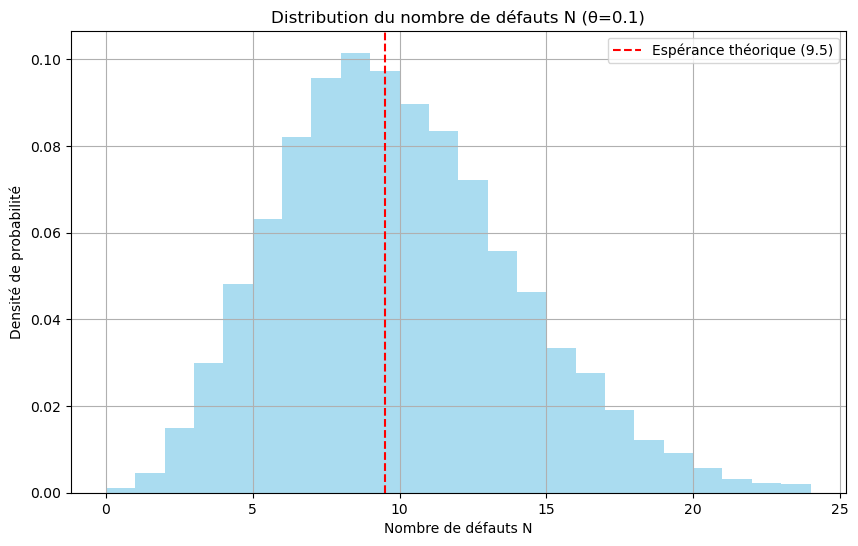

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Paramètres
d = 100  # nombre d'entreprises
lambda_ = 0.02
T = 5
theta = 0.1
u0 = np.exp(-lambda_ * T)  # seuil = e^{-0.1} ≈ 0.9048
n_values = [5, 10, 30]  # valeurs de n à tester
M = 100000  # nombre de simulations Monte Carlo

# Initialisation des compteurs
counts = {n: 0 for n in n_values}

# Simulation
np.random.seed(42)  # Pour la reproductibilité

for _ in range(M):
    # Générer ξ ~ Gamma(shape=1/theta, scale=1)
    xi = np.random.gamma(shape=1/theta, scale=1)
    
    # Générer les V_i ~ Uniforme[0,1]
    V = np.random.uniform(size=d)
    
    # Calculer les U_i = (ξ / (ξ - log(V_i)))^{1/theta}
    # Note: ξ - log(V_i) > 0 car ξ > 0 et -log(V_i) ≥ 0
    logV = -np.log(V)  # attention: -log(V_i)
    U = (xi / (xi + logV)) ** (1/theta)  # + car logV = -log(V)
    
    # Calculer N = nombre de défauts (U_i ≥ u0)
    N = np.sum(U >= u0)
    
    # Mettre à jour les compteurs pour chaque n
    for n in n_values:
        if N >= n:
            counts[n] += 1

# Calcul des probabilités
probabilities = {n: counts[n] / M for n in n_values}

# Affichage des résultats
print("Résultats de la simulation (M = 100,000):")
for n in n_values:
    print(f"ℙ(N ≥ {n}) = {probabilities[n]:.6f}")

# Visualisation de la distribution de N 
all_N = []  # Stocker toutes les valeurs de N pour l'histogramme

for _ in range(10000):  # On refait 10,000 simuls pour le plot
    xi = np.random.gamma(shape=1/theta, scale=1)
    V = np.random.uniform(size=d)
    logV = -np.log(V)
    U = (xi / (xi + logV)) ** (1/theta)
    N = np.sum(U >= u0)
    all_N.append(N)

plt.figure(figsize=(10, 6))
plt.hist(all_N, bins=range(0, 25), density=True, alpha=0.7, color='skyblue')
plt.axvline(x=9.5, color='r', linestyle='--', label='Espérance théorique (9.5)')
plt.title('Distribution du nombre de défauts N (θ=0.1)')
plt.xlabel('Nombre de défauts N')
plt.ylabel('Densité de probabilité')
plt.legend()
plt.grid(True)
plt.show()

**Interprétation**
$$
$$
$ \mathbb{P}(N \geq 5) \approx 1 $ : Très probable car l'espérance théorique de $ N $ est $ 100 \times (1 - e^{-0.1}) \approx 9.5 $.
$$
$$
$ \mathbb{P}(N \geq 10) \approx 0.46 $ : Cohérent avec une dépendance faible ($\theta = 0.1$) introduite par la copule de S3..
$$
$$
$ \mathbb{P}(N \geq 30) \approx 0 $ : Événement très rare, même avec dépendance, car 30 défauts correspond à plus de 3 fois l'espérance.

**S4. b)**

In [6]:
import numpy as np
from scipy.stats import gamma, binom

# Paramètres
d = 100
lambda_ = 0.02
T = 5
theta = 0.1
u0 = np.exp(-lambda_ * T)  # e^{-0.1} ≈ 0.904837
n_values = [5, 10, 30]
M = 100000  # nombre de simulations

# Initialisation des compteurs
counts = {n: 0 for n in n_values}

np.random.seed(42)



for _ in range(M):
    # Générer ξ ~ Gamma(10, 1)
    shape = 1/theta
    scale = 1.0
    xi = np.random.gamma(shape=shape, scale=scale)
    
    # Générer V_i ~ Uniforme[0,1]
    V = np.random.uniform(size=d)
    
    # Calculer les 1 - U_i = ψ(-log(V_i)/ξ)
    logV = -np.log(V)  
    one_minus_U = (xi / (xi + logV)) ** (1/theta)  # + car logV est déjà -log(V)
    
    # Calculer U_i = 1 - (1 - U_i)
    U = 1 - one_minus_U
    
    # Calculer N = nombre de défauts (U_i ≥ u0)
    N = np.sum(U >= u0)
    
    
    # Mettre à jour les compteurs
    for n in n_values:
        if N >= n:
            counts[n] += 1

# Calcul des probabilités
probabilities = {n: counts[n] / M for n in n_values}


print("Résultats de la simulation (M = 100,000):")
for n in n_values:
    print(f"ℙ(N ≥ {n}) = {probabilities[n]:.6f}")

Résultats de la simulation (M = 100,000):
ℙ(N ≥ 5) = 0.701470
ℙ(N ≥ 10) = 0.399280
ℙ(N ≥ 30) = 0.024250


**Interprétation**
$$
$$
On remarque que les valeurs de $N$ sont plus étalées que dans le cas précédent, ce qui explique les différences entre les probabilités.

**S4. c)**

In [7]:
import numpy as np
import scipy.stats as sps

np.random.seed(42)

# Paramètres
d = 100
lambda_ = 0.02
T = 5
n_list = [5,10,30]
rho_list = [0.5,0.9]
nb_sim = 10000

for rho in rho_list:
    print(f"=== Résultats pour rho = {rho} ===")
    
    #création L
    L = ((np.sqrt(1+(100-1)*rho)-np.sqrt(1-rho))/100) *np.ones((100,100)) + np.sqrt(1-rho)*np.eye(100)
    
    # Stockage des résultats
    N_all = []
    
    for _ in range(nb_sim):
        # Simulation normales corrélées
        Z = np.random.randn(d)
        X = L @ Z
        # Transformation en uniforms
        U = sps.norm.cdf(X)
        # Transformation en temps de défauts
        T_i = -1/lambda_ * np.log(U)
        # Calcul du nombre de défauts avant T
        N = np.sum(T_i <= T)
        N_all.append(N)
    
    N_all = np.array(N_all)
    
    # Estimation de P(N >= n) pour chaque n
    for n in n_list:
        prob = np.mean(N_all >= n)
        # Intervalle de confiance 95%
        std_err = np.sqrt(prob*(1-prob)/nb_sim)
        IC = (prob - 1.96*std_err, prob + 1.96*std_err)
        print(f"P(N >= {n}) = {prob:.4f}, IC95% = [{IC[0]:.4f}, {IC[1]:.4f}]")
    
    print()

=== Résultats pour rho = 0.5 ===
P(N >= 5) = 0.4281, IC95% = [0.4184, 0.4378]
P(N >= 10) = 0.2879, IC95% = [0.2790, 0.2968]
P(N >= 30) = 0.0954, IC95% = [0.0896, 0.1012]

=== Résultats pour rho = 0.9 ===
P(N >= 5) = 0.2083, IC95% = [0.2003, 0.2163]
P(N >= 10) = 0.1704, IC95% = [0.1630, 0.1778]
P(N >= 30) = 0.1119, IC95% = [0.1057, 0.1181]



**Interprétation**
$$
$$
Ainsi, on peut remarquer qu'une augmentation de $\rho$ entraîne une augmentation de la corrélation des défauts : la probabilité d'avoir beaucoup de défauts en même temps augmente, tandis que celle d'avoir un nombre moyen de défauts diminue. La corrélation des défauts augmente donc le risque systématique.